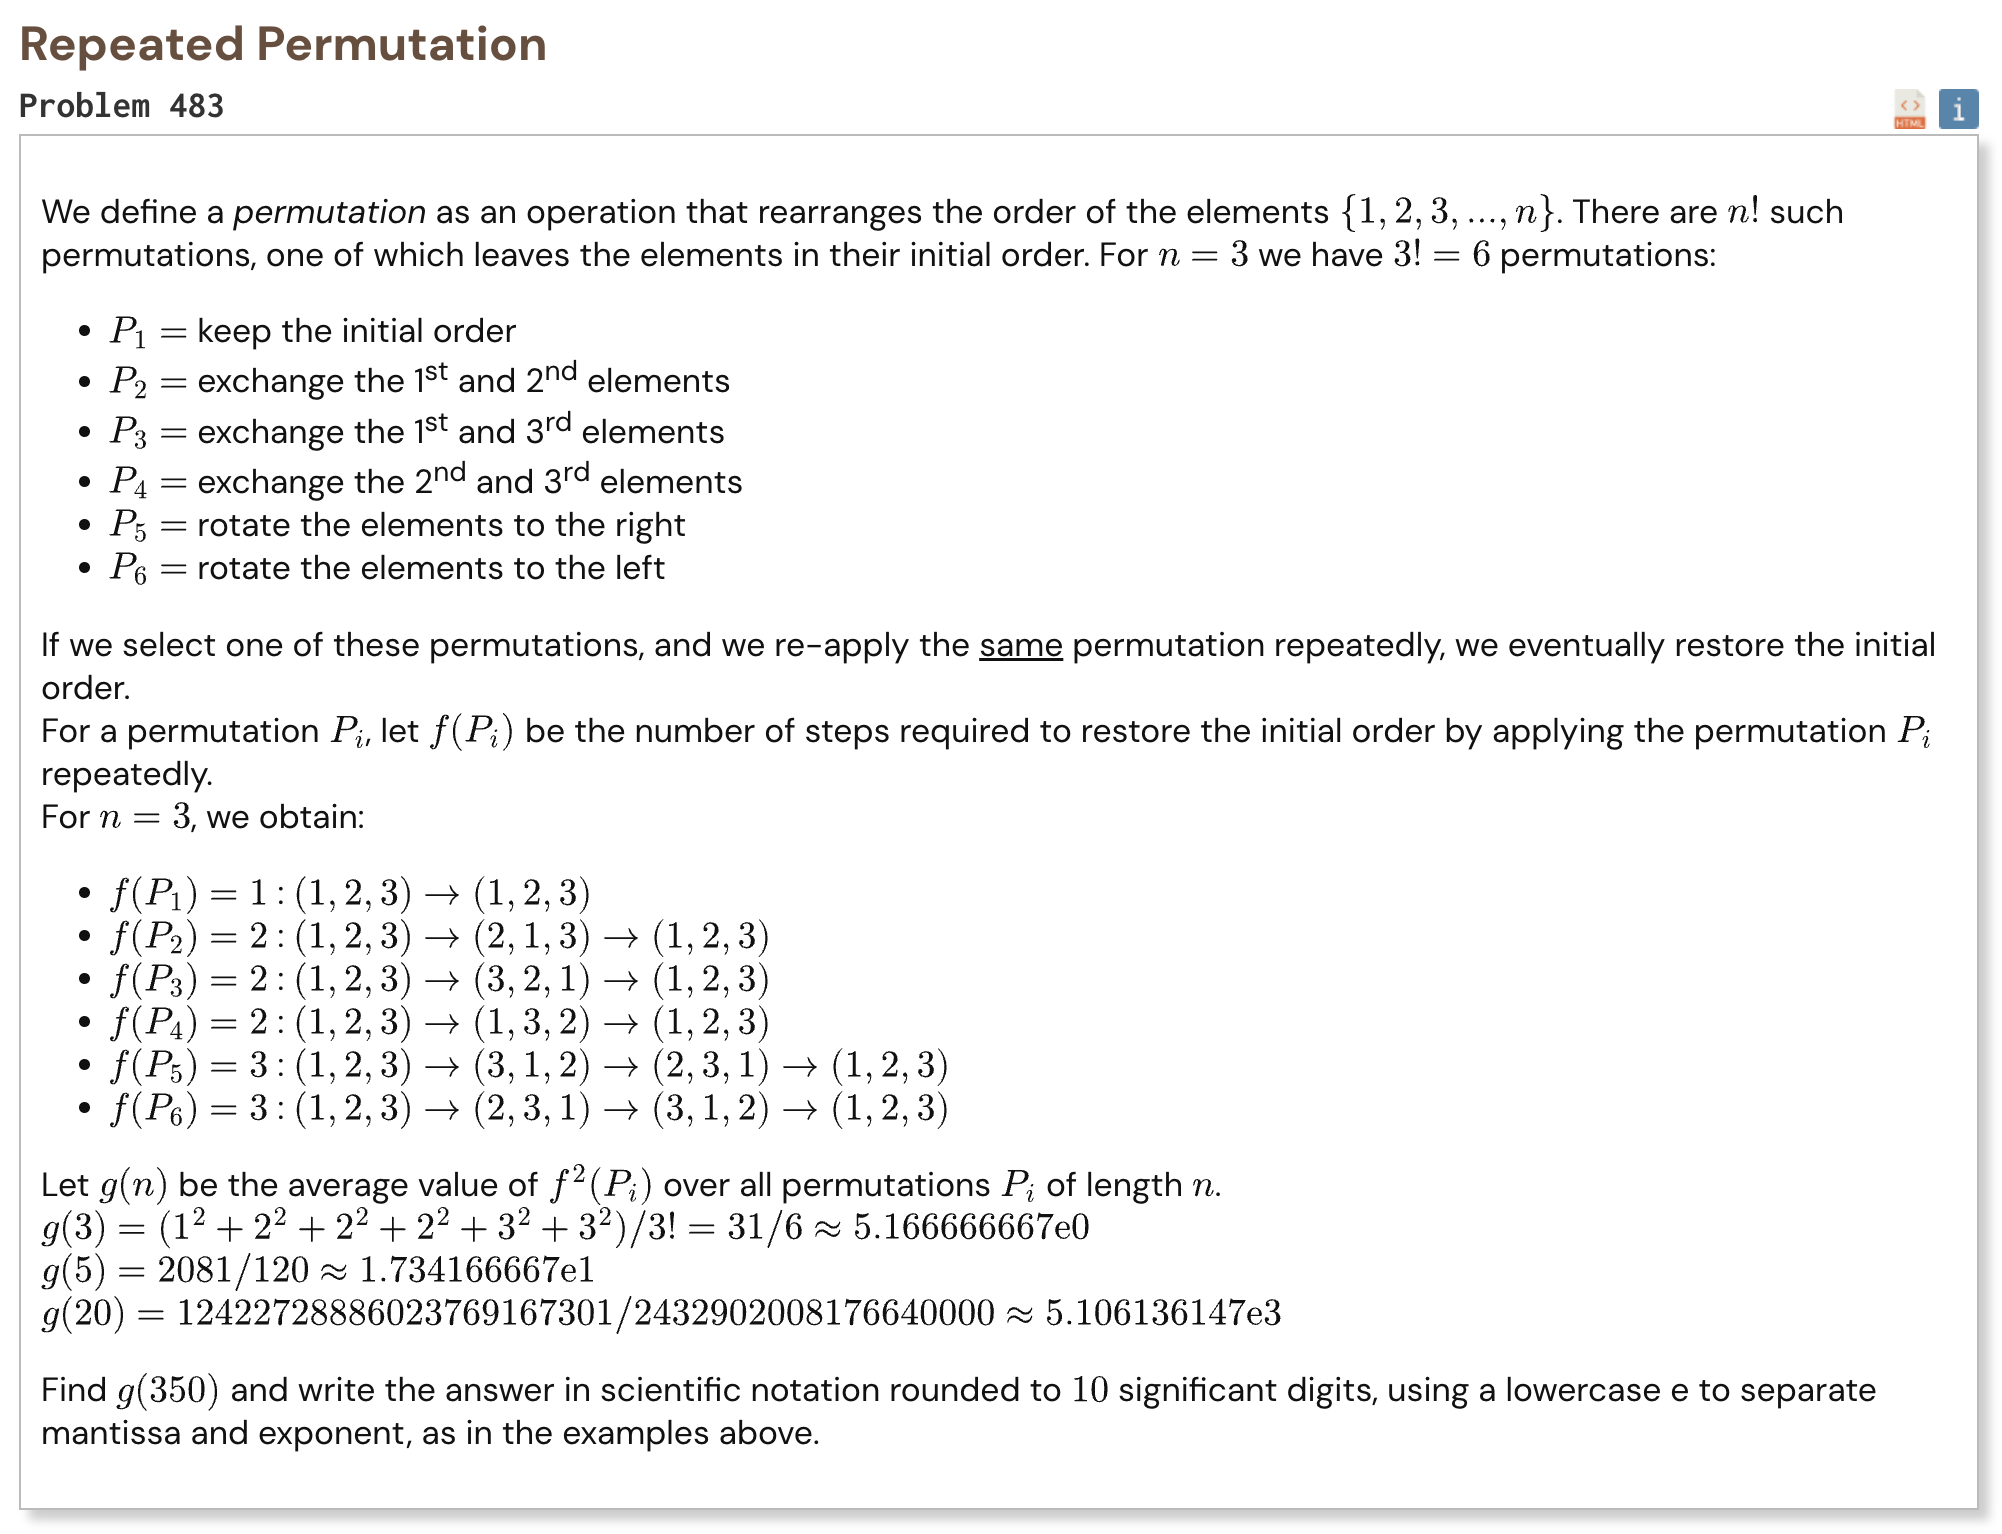

## Initial approach

- split each permutation into cycles
- the repeat count is the least common multiple of the cycle lengths
- count cycle structures instead of individual permutations
- use dynamic programming to track total length and the current least common multiple
- process cycle lengths by their largest prime factor to keep the number of states small
- absorb completed prime factors into the stored weight
- evaluate the states for length 350 and format the result in scientific notation

In [1]:
%%time

from collections import defaultdict
from math import gcd

N = 350

def lcm(a, b):
    return a // gcd(a, b) * b

def g(n):
    largest_prime_factor = [0] * (n + 1)

    for p in range(2, n + 1):
        if largest_prime_factor[p] != 0:
            continue

        for value in range(p, n + 1, p):
            largest_prime_factor[value] = p

    histograms = [defaultdict(float) for _ in range(n + 1)]

    weight = 1.0

    for length in range(n + 1):
        if length > 0:
            weight /= length

        histograms[length][1] = weight

    for p in range(n, 1, -1):
        if largest_prime_factor[p] != p:
            continue

        for cycle_length in range(p, n + 1, p):
            if largest_prime_factor[cycle_length] != p:
                continue

            next_histograms = [
                defaultdict(float)
                for _ in range(n + 1)
            ]

            multiplicity = 0
            cycle_weight = 1.0

            while multiplicity * cycle_length <= n:
                added_length = multiplicity * cycle_length
                added_lcm = 1 if multiplicity == 0 else cycle_length

                for current_length in range(n - added_length + 1):
                    for current_lcm, current_weight in histograms[current_length].items():
                        new_lcm = lcm(current_lcm, added_lcm)

                        next_histograms[current_length + added_length][new_lcm] += (
                            current_weight * cycle_weight
                        )

                multiplicity += 1
                cycle_weight /= cycle_length * multiplicity

            histograms = next_histograms

        for length in range(n + 1):
            reduced = defaultdict(float)

            for current_lcm, current_weight in histograms[length].items():
                while current_lcm % p == 0:
                    current_lcm //= p
                    current_weight *= p * p

                reduced[current_lcm] += current_weight

            histograms[length] = reduced

    result = 0.0

    for current_lcm, current_weight in histograms[n].items():
        result += current_lcm * current_lcm * current_weight

    return result

result = g(N)

print("Result:", f"{result:.9e}")

Result: 4.993401567e+22
CPU times: user 983 ms, sys: 3.92 ms, total: 987 ms
Wall time: 987 ms
